# Amazon Fulfillment: Optimizing Labor Cost and On-Time Order Processing
## Unit 11 — Multi-Objective Optimization Engine (Part 1)
**Target:** Amazon-style regional fulfillment center (independent educational simulation)  
**Objectives:** Minimize daily variable processing cost (USD) and maximize on-time processing (%)  
**Decision variables:** Workers scheduled per shift; share of orders expedited.

This notebook implements the exact company, tradeoff and data strategy from the approved Unit 9 proposal. It does **not** claim access to Amazon internal data.

## Project overview
Warehouse managers must balance staffing and expedited processing costs against orders ready before carrier deadlines. More labor and expediting can improve service but increase variable spending. We evaluate 100 synthetic configurations under a common demand profile, identify nondominated solutions, and compare five strategic choices. **Phase 1 analyzes mathematical efficiency only; constraint-aware decision-agent logic belongs to Phase 2.**

## Section 1 — Data acquisition and reproducibility
Synthetic operational data are generated using a deterministic Python model and saved in `data/fulfillment_scenarios.csv`. Assumptions and limitations are documented in `data/SIMULATION_METHOD.md`. Published Amazon reports motivate the problem, not the simulated numerical parameters.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
DATA = Path('data'); IMAGES = Path('images'); IMAGES.mkdir(exist_ok=True)
SEED = 42
HOURLY_ARRIVALS = np.array([145,170,200,225,245,255,240,215])
rows=[]
for workers in range(30,80,5):
    for expedited_pct in range(0,50,5):
        exp_orders=min(HOURLY_ARRIVALS.sum()*expedited_pct/100,280)
        regular_capacity=workers*4.2*7.5
        effective_capacity=regular_capacity*(1-0.12*expedited_pct/100)+exp_orders*0.65
        peak_penalty=max(0,(HOURLY_ARRIVALS.max()-workers*4.2)*0.018)
        on_time=np.clip(100*effective_capacity/HOURLY_ARRIVALS.sum()-peak_penalty,0,99.4)
        cost=workers*7.5*22+exp_orders*2.8
        rows.append([workers,expedited_pct,round(cost,2),round(on_time,2),int(HOURLY_ARRIVALS.sum()),round(exp_orders,1),round(effective_capacity,1)])
columns=['workers_per_shift','expedited_share_pct','daily_cost_usd','on_time_pct','daily_orders','expedited_orders','effective_capacity_orders']
generated=pd.DataFrame(rows,columns=columns)
file=DATA/'fulfillment_scenarios.csv'
assert file.exists(), 'Place the provided CSV in data/'
df=pd.read_csv(file)
assert (df[['workers_per_shift','expedited_share_pct']].to_numpy()==generated[['workers_per_shift','expedited_share_pct']].to_numpy()).all()
assert np.allclose(df[['daily_cost_usd','on_time_pct','daily_orders','expedited_orders','effective_capacity_orders']],generated[['daily_cost_usd','on_time_pct','daily_orders','expedited_orders','effective_capacity_orders']],atol=0.11)
print('Reproducible dataset loaded:',df.shape)
display(df.head())

Reproducible dataset loaded: (100, 7)


,workers_per_shift,expedited_share_pct,daily_cost_usd,on_time_pct,daily_orders,expedited_orders,effective_capacity_orders
0,30,0,4950.0,53.43,1695,0.0,945.0
1,30,5,5187.3,56.35,1695,84.8,994.4
2,30,10,5424.6,59.26,1695,169.5,1043.8
3,30,15,5661.9,62.18,1695,254.2,1093.3
4,30,20,5734.0,62.83,1695,280.0,1104.3


## Section 2 — Data exploration and validation

Missing values: {'workers_per_shift': 0, 'expedited_share_pct': 0, 'daily_cost_usd': 0, 'on_time_pct': 0, 'daily_orders': 0, 'expedited_orders': 0, 'effective_capacity_orders': 0}
Types: {'workers_per_shift': dtype('int64'), 'expedited_share_pct': dtype('int64'), 'daily_cost_usd': dtype('float64'), 'on_time_pct': dtype('float64'), 'daily_orders': dtype('int64'), 'expedited_orders': dtype('float64'), 'effective_capacity_orders': dtype('float64')}
Objective correlation: 0.873


,workers_per_shift,expedited_share_pct,daily_cost_usd,on_time_pct,daily_orders,expedited_orders,effective_capacity_orders
count,100.00,100.00,100.00,100.00,100.0,100.00,100.00
mean,52.50,22.50,9275.28,89.25,1695.0,218.85,1751.35
std,14.43,14.43,2396.82,14.01,0.0,96.39,444.49
min,30.00,0.00,4950.00,53.43,1695.0,0.00,945.00
25%,40.00,10.00,7384.00,80.28,1695.0,169.50,1387.20
50%,52.50,22.50,9054.50,99.40,1695.0,280.00,1725.85
75%,65.00,35.00,11509.00,99.40,1695.0,280.00,2135.70
max,75.00,45.00,13159.00,99.40,1695.0,280.00,2487.80


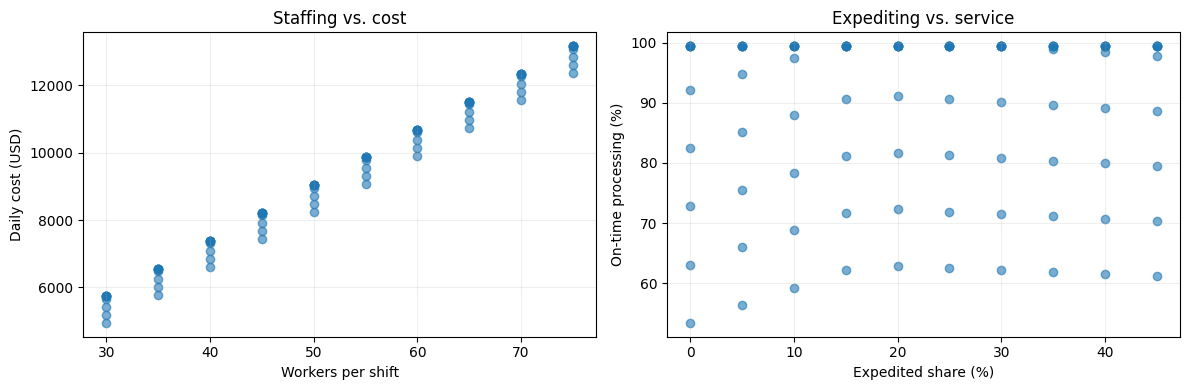

In [2]:
assert len(df)==100
assert not df.isna().any().any()
assert not df.duplicated(['workers_per_shift','expedited_share_pct']).any()
assert df['on_time_pct'].between(0,100).all()
assert (df['daily_cost_usd']>0).all()
assert df['workers_per_shift'].nunique()==10 and df['expedited_share_pct'].nunique()==10
print('Missing values:',df.isna().sum().to_dict())
print('Types:',df.dtypes.to_dict())
print('Objective correlation:',round(df['daily_cost_usd'].corr(df['on_time_pct']),3))
display(df.describe().round(2))
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].scatter(df.workers_per_shift,df.daily_cost_usd,alpha=.6)
ax[0].set(xlabel='Workers per shift',ylabel='Daily cost (USD)',title='Staffing vs. cost')
ax[1].scatter(df.expedited_share_pct,df.on_time_pct,alpha=.6)
ax[1].set(xlabel='Expedited share (%)',ylabel='On-time processing (%)',title='Expediting vs. service')
for a in ax:a.grid(alpha=.2)
fig.tight_layout();fig.savefig(IMAGES/'data_exploration.png',dpi=200);plt.show()

**Data-quality interpretation:** All 100 configurations are complete, unique, and within their intended ranges. Cost and service outcomes are generated from explicitly documented synthetic assumptions. A positive correlation between cost and on-time service is consistent with the central tradeoff, but does not establish real-world predictive validity.

## Section 3 — Complete Pareto frontier calculation
A configuration is dominated when another configuration costs **no more** and delivers **at least as much** on-time processing, with at least one strict improvement. We retain all nondominated points, including equal-objective ties.

In [3]:
def pareto_mask(data,cost_col='daily_cost_usd',service_col='on_time_pct'):
    cost=data[cost_col].to_numpy(dtype=float)
    service=data[service_col].to_numpy(dtype=float)
    efficient=np.ones(len(data),dtype=bool)
    for i in range(len(data)):
        dominated_by=((cost<=cost[i]) & (service>=service[i]) & ((cost<cost[i]) | (service>service[i])))
        efficient[i]=not dominated_by.any()
    return efficient

df['is_pareto_optimal']=pareto_mask(df)
frontier=df[df.is_pareto_optimal].copy().sort_values(['daily_cost_usd','on_time_pct'])
dominated=df[~df.is_pareto_optimal].copy()
print(f'Analyzed: {len(df)} | Efficient: {len(frontier)} | Dominated: {len(dominated)} | Efficiency: {len(frontier)/len(df):.1%}')
assert len(frontier)>1 and len(dominated)>0
assert pareto_mask(frontier).all()
display(frontier[['workers_per_shift','expedited_share_pct','daily_cost_usd','on_time_pct']])

Analyzed: 100 | Efficient: 24 | Dominated: 76 | Efficiency: 24.0%


,workers_per_shift,expedited_share_pct,daily_cost_usd,on_time_pct
0,30,0,4950.0,53.43
1,30,5,5187.3,56.35
2,30,10,5424.6,59.26
3,30,15,5661.9,62.18
4,30,20,5734.0,62.83
10,35,0,5775.0,63.10
11,35,5,6012.3,65.96
12,35,10,6249.6,68.82
13,35,15,6486.9,71.68
14,35,20,6559.0,72.28


### Dominated solutions: specific improvements

In [4]:
examples=[]
for _,bad in dominated.sample(min(3,len(dominated)),random_state=SEED).iterrows():
    better=frontier[(frontier.daily_cost_usd<=bad.daily_cost_usd)&(frontier.on_time_pct>=bad.on_time_pct)]
    assert len(better)>0
    good=better.sort_values(['daily_cost_usd','on_time_pct'],ascending=[True,False]).iloc[0]
    examples.append({'inefficient_workers':int(bad.workers_per_shift),'inefficient_expedite_pct':int(bad.expedited_share_pct),
                     'better_workers':int(good.workers_per_shift),'better_expedite_pct':int(good.expedited_share_pct),
                     'cost_saving_usd':round(bad.daily_cost_usd-good.daily_cost_usd,2),
                     'service_gain_pp':round(good.on_time_pct-bad.on_time_pct,2)})
display(pd.DataFrame(examples))
# Totals cannot generally be ordered across the frontier; report both without asserting dominance.
best_dominated=dominated.loc[(dominated.on_time_pct-dominated.daily_cost_usd/1000).idxmax()]
lowest_service_frontier=frontier.loc[frontier.on_time_pct.idxmin()]
print('Illustrative comparison only (NOT necessarily a dominance relation):')
print('Selected dominated:',best_dominated[['daily_cost_usd','on_time_pct']].to_dict())
print('Lowest-service efficient:',lowest_service_frontier[['daily_cost_usd','on_time_pct']].to_dict())

,inefficient_workers,inefficient_expedite_pct,better_workers,better_expedite_pct,cost_saving_usd,service_gain_pp
0,30,45,30,15,72.1,1.02
1,55,45,50,15,897.1,0.00
2,40,25,40,20,0.0,0.44


Illustrative comparison only (NOT necessarily a dominance relation):
Selected dominated: {'daily_cost_usd': 9034.0, 'on_time_pct': 99.4}
Lowest-service efficient: {'daily_cost_usd': 4950.0, 'on_time_pct': 53.43}


## Section 4 — Five strategic points
To compare objectives with different units, both are normalized to a 0–1 benefit scale **over the observed frontier**. Balanced maximizes equal-weight total normalized benefit; equity minimizes the difference between normalized benefits. The 60/40 strategy weights cost savings at 60% and service at 40%. These are descriptive strategy points, not constraint-filtered agent recommendations.

In [5]:
f=frontier.copy()
cmin,cmax=f.daily_cost_usd.min(),f.daily_cost_usd.max()
smin,smax=f.on_time_pct.min(),f.on_time_pct.max()
f['cost_benefit']=(cmax-f.daily_cost_usd)/(cmax-cmin)
f['service_benefit']=(f.on_time_pct-smin)/(smax-smin)
f['balanced_score']=0.5*f.cost_benefit+0.5*f.service_benefit
f['equity_gap']=(f.cost_benefit-f.service_benefit).abs()
f['weighted_score']=0.6*f.cost_benefit+0.4*f.service_benefit
strategies={
 'Balanced (50/50)':f.balanced_score.idxmax(),
 'Equity (min normalized gap)':f.equity_gap.idxmin(),
 'Cost priority':f.daily_cost_usd.idxmin(),
 'On-time priority':f.on_time_pct.idxmax(),
 'Weighted (60% cost / 40% service)':f.weighted_score.idxmax(),
}
comparison=pd.DataFrame([{'strategy':name,**f.loc[idx,['workers_per_shift','expedited_share_pct','daily_cost_usd','on_time_pct']].to_dict()} for name,idx in strategies.items()])
display(comparison)
comparison.to_csv(DATA/'strategy_comparison.csv',index=False)

,strategy,workers_per_shift,expedited_share_pct,daily_cost_usd,on_time_pct
0,Balanced (50/50),50,0,8250.0,92.11
1,Equity (min normalized gap),40,5,6837.3,75.57
2,Cost priority,30,0,4950.0,53.43
3,On-time priority,50,15,8961.9,99.40
4,Weighted (60% cost / 40% service),30,0,4950.0,53.43


## Section 5 — Executive-ready three-panel visualization

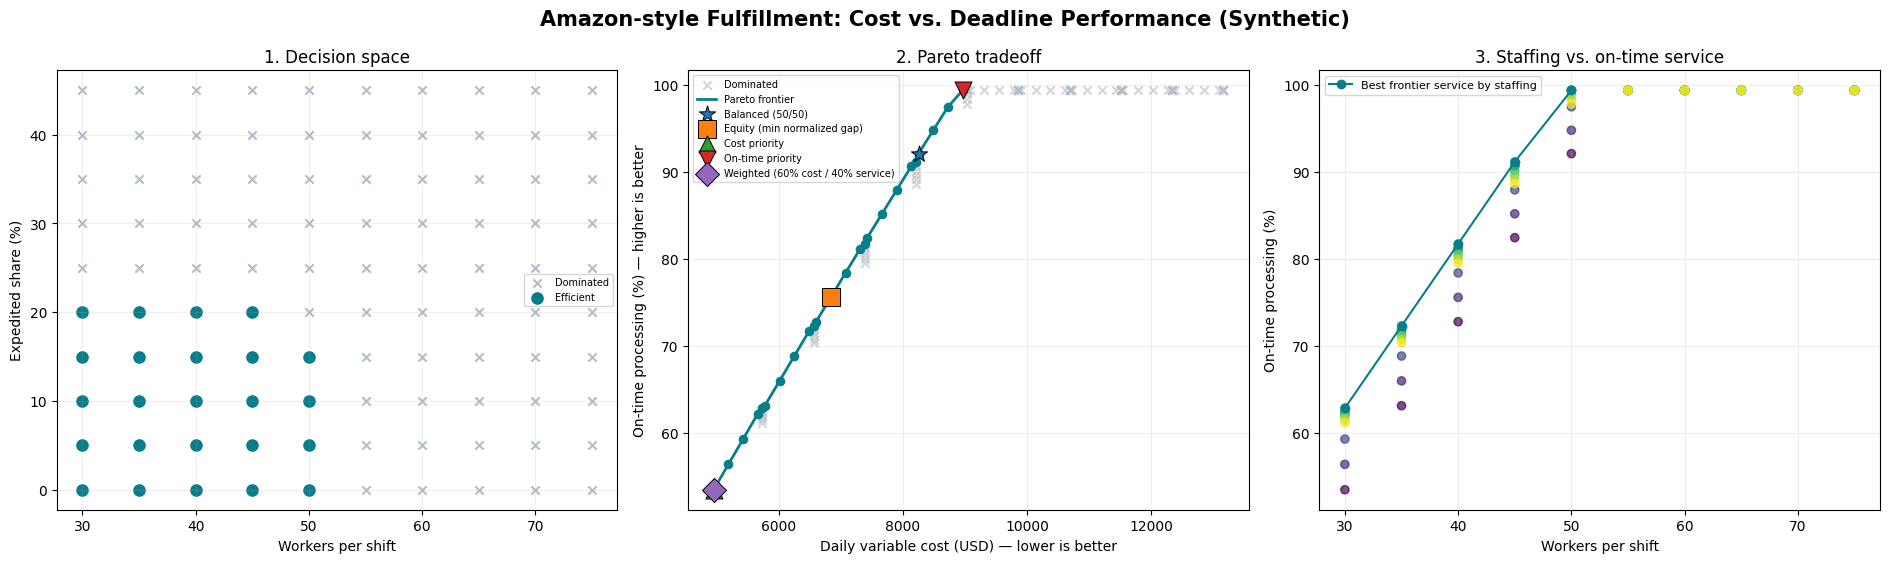

In [6]:
fig,ax=plt.subplots(1,3,figsize=(19,5.7))
ax[0].scatter(dominated.workers_per_shift,dominated.expedited_share_pct,c='#b5bdc7',marker='x',label='Dominated')
ax[0].scatter(frontier.workers_per_shift,frontier.expedited_share_pct,c='#087e8b',s=65,label='Efficient')
ax[0].set(xlabel='Workers per shift',ylabel='Expedited share (%)',title='1. Decision space')
ax[1].scatter(dominated.daily_cost_usd,dominated.on_time_pct,c='#b5bdc7',marker='x',alpha=.6,label='Dominated')
ax[1].plot(frontier.daily_cost_usd,frontier.on_time_pct,c='#087e8b',lw=2,label='Pareto frontier')
ax[1].scatter(frontier.daily_cost_usd,frontier.on_time_pct,c='#087e8b',s=35)
markers=['*','s','^','v','D']
for (name,idx),marker in zip(strategies.items(),markers):
    point=f.loc[idx]
    ax[1].scatter(point.daily_cost_usd,point.on_time_pct,marker=marker,s=150,edgecolors='black',linewidths=.7,label=name,zorder=5)
ax[1].set(xlabel='Daily variable cost (USD) — lower is better',ylabel='On-time processing (%) — higher is better',title='2. Pareto tradeoff')
ax[2].scatter(df.workers_per_shift,df.on_time_pct,c=df.expedited_share_pct,cmap='viridis',alpha=.7)
ax[2].plot(frontier.groupby('workers_per_shift').on_time_pct.max(),marker='o',c='#087e8b',label='Best frontier service by staffing')
ax[2].set(xlabel='Workers per shift',ylabel='On-time processing (%)',title='3. Staffing vs. on-time service')
for a in ax:a.grid(alpha=.2);a.legend(fontsize=7,loc='best') if a is not ax[2] else a.legend(fontsize=8)
fig.suptitle('Amazon-style Fulfillment: Cost vs. Deadline Performance (Synthetic)',fontsize=15,fontweight='bold')
fig.tight_layout();fig.savefig(IMAGES/'pareto_frontier_analysis.png',dpi=220,bbox_inches='tight');plt.show()

## Section 6 — Findings, implications and limitations
The outputs above quantify how many of the 100 synthetic configurations are nondominated and compare five strategic perspectives. Dominated configurations can be improved in cost, service, or both without sacrificing either objective. The efficient frontier illustrates why there is no single universally best configuration: different stakeholders may prefer lower operating expense or greater deadline reliability.

**Limitations:** The on-time rate is a stylized throughput-based proxy rather than order-level deadline simulation. Hourly demand is shared across scenarios, and labor productivity, costs, and lane behavior are assumed rather than calibrated to Amazon records. Some service values saturate at 99.4%, which can produce ties. Phase 2 should apply budget, workstation, break, lane, and minimum 90% service constraints to the efficient configurations, report infeasibility explicitly, and add heuristic recommendations. Real-world use would require operational validation and more detailed queuing and deadline modeling.